In [29]:
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from pathlib import Path

from src.lda import LDA
from src.knn import KNN
from src.gmm import GMMClassifier
from src.svm import OneVsRestSVM
from src.pca import PCA

In [5]:
DATASET_PATH = Path(
    r"C:\Users\hp\OneDrive\Desktop\ml lab8\team8\data\TEAM_8"
)

# Check the required folders.
for split in ["train", "dev", "test"]:
    if not (DATASET_PATH / split).is_dir():
        raise FileNotFoundError(
            f"Missing folder: {DATASET_PATH / split}"
        )

print("Dataset folder found.")
print("Training, development, and testing folders are available.")

Dataset folder found.
Training, development, and testing folders are available.


In [6]:
CLASSES = [3, 4, 7]


def load_dataset(split):
    features = []
    labels = []

    for digit in CLASSES:
        folder = DATASET_PATH / split / str(digit)
        image_files = sorted(folder.glob("*.png"))

        if not image_files:
            raise FileNotFoundError(
                f"No PNG images found in: {folder}"
            )

        for image_file in image_files:
            with Image.open(image_file) as img:
                img = img.convert("L")

                if img.size != (28, 28):
                    raise ValueError(
                        f"Expected a 28×28 image: {image_file}"
                    )

                features.append(
                    np.asarray(img, dtype=np.float32).flatten()
                )

            labels.append(digit)

    return np.asarray(features), np.asarray(labels, dtype=int)


X_train, y_train = load_dataset("train")
X_dev, y_dev = load_dataset("dev")
X_test, y_test = load_dataset("test")

print("Training:", X_train.shape)
print("Development:", X_dev.shape)
print("Testing:", X_test.shape)

Training: (14550, 784)
Development: (3688, 784)
Testing: (3020, 784)


In [4]:
for name, labels in [
    ("Training", y_train),
    ("Development", y_dev),
    ("Testing", y_test)
]:
    print("\n", name)
    for digit in CLASSES:
        print(f"Digit {digit}: {np.sum(labels == digit)} images")


 Training
Digit 3: 4886 images
Digit 4: 4681 images
Digit 7: 4983 images

 Development
Digit 3: 1245 images
Digit 4: 1161 images
Digit 7: 1282 images

 Testing
Digit 3: 1010 images
Digit 4: 982 images
Digit 7: 1028 images


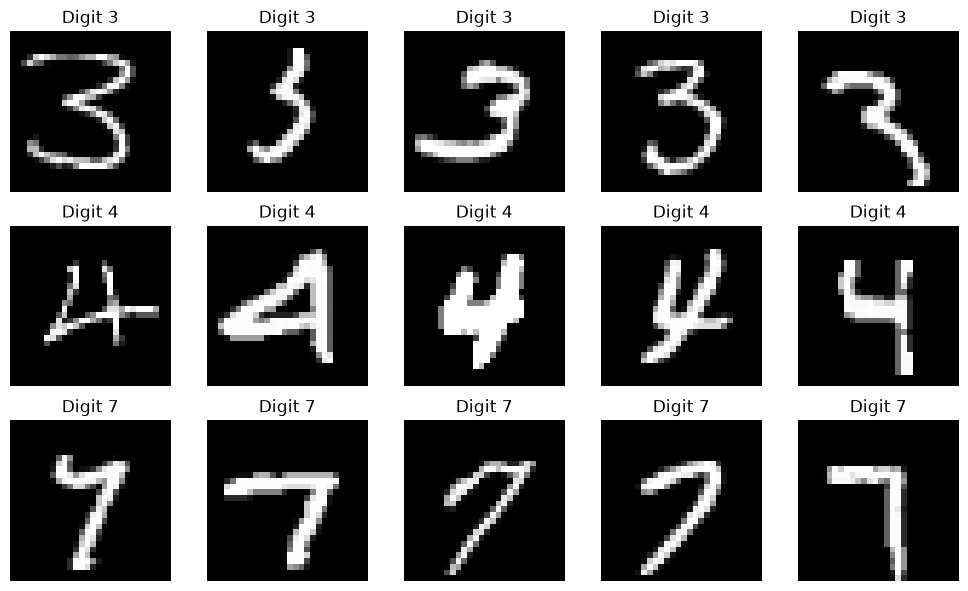

In [5]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 5, figsize=(10, 6))

for row, digit in enumerate(CLASSES):
    indices = np.where(y_train == digit)[0][:5]

    for col, idx in enumerate(indices):
        axes[row, col].imshow(
            X_train[idx].reshape(28, 28),
            cmap="gray"
        )
        axes[row, col].set_title(f"Digit {digit}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

In [13]:
# Calculate scaling statistics from training data only.
train_mean = X_train.mean(axis=0)
train_std = X_train.std(axis=0)

# Constant pixel columns must not cause division by zero.
train_std_safe = np.where(train_std == 0, 1.0, train_std)

X_train_scaled = (X_train - train_mean) / train_std_safe
X_dev_scaled = (X_dev - train_mean) / train_std_safe
X_test_scaled = (X_test - train_mean) / train_std_safe

In [14]:
def accuracy_score_manual(y_true, y_pred):
    return np.mean(np.asarray(y_true) == np.asarray(y_pred))


def confusion_matrix_manual(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    labels = np.unique(np.concatenate([y_true, y_pred]))

    matrix = np.array([
        [
            np.sum((y_true == actual) & (y_pred == predicted))
            for predicted in labels
        ]
        for actual in labels
    ], dtype=int)

    return matrix


def show_evaluation(name, y_true, y_pred):
    accuracy = accuracy_score_manual(y_true, y_pred)
    matrix = confusion_matrix_manual(y_true, y_pred)

    labels = np.unique(np.concatenate([y_true, y_pred]))

    print(f"{name} validation accuracy: {100 * accuracy:.3f}%")
    print("\nConfusion matrix:")

    print(pd.DataFrame(
        matrix,
        index=[f"Actual {label}" for label in labels],
        columns=[f"Predicted {label}" for label in labels]
    ))

    return accuracy

In [7]:
import pandas as pd

def accuracy_score_manual(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    return np.mean(y_true == y_pred)


def confusion_matrix_manual(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    labels = np.unique(np.concatenate([y_true, y_pred]))

    matrix = np.zeros(
        (len(labels), len(labels)),
        dtype=int
    )

    label_to_index = {
        label: index
        for index, label in enumerate(labels)
    }

    for actual, predicted in zip(y_true, y_pred):
        matrix[
            label_to_index[actual],
            label_to_index[predicted]
        ] += 1

    return matrix


def show_evaluation(name, y_true, y_pred):
    accuracy = accuracy_score_manual(y_true, y_pred)
    matrix = confusion_matrix_manual(y_true, y_pred)

    labels = np.unique(np.concatenate([y_true, y_pred]))

    print(f"{name} validation accuracy: {100 * accuracy:.3f}%")
    print("\nConfusion matrix:")

    print(pd.DataFrame(
        matrix,
        index=[f"Actual {label}" for label in labels],
        columns=[f"Predicted {label}" for label in labels]
    ))

    return accuracy

LDA validation accuracy: 97.017%

Confusion matrix:
          Predicted 3  Predicted 4  Predicted 7
Actual 3         1194           15           36
Actual 4            7         1147            7
Actual 7           11           34         1237


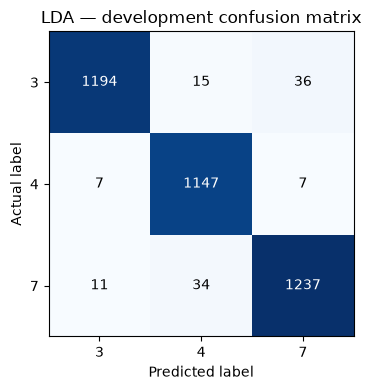

In [53]:
#LDA
lda_model = LDA()
lda_model.fit(X_train_scaled, y_train)

# MNIST calls its validation split "dev".
lda_val_predictions = lda_model.predict(X_dev_scaled)

lda_val_accuracy = show_evaluation(
    "LDA",
    y_dev,
    lda_val_predictions
)

validation_results = [{
    "Classifier": "LDA",
    "Setting": "Shared covariance",
    "Validation accuracy (%)": 100 * lda_val_accuracy
}]

matrix = confusion_matrix_manual(y_dev, lda_val_predictions)
labels = np.unique(np.concatenate([y_dev, lda_val_predictions]))

plt.figure(figsize=(5, 4))
plt.imshow(matrix, cmap="Blues")

for row in range(len(labels)):
    for column in range(len(labels)):
        plt.text(
            column, row, matrix[row, column],
            ha="center",
            va="center",
            color="white" if matrix[row, column] > matrix.max() / 2
            else "black"
        )

plt.xticks(range(len(labels)), labels)
plt.yticks(range(len(labels)), labels)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title("LDA — development confusion matrix")
plt.tight_layout()
plt.show()

In [18]:
#KNN
knn_model = KNN(batch_size=128)
knn_model.fit(X_train_scaled, y_train)

neighbor_values = [3, 5, 7, 11]

knn_val_predictions = knn_model.predict_for_k_values(
    X_dev_scaled,
    neighbor_values
)

knn_rows = []

for k in neighbor_values:
    accuracy = accuracy_score_manual(
        y_dev, knn_val_predictions[k]
    )

    knn_rows.append({
        "Neighbours": k,
        "Validation accuracy (%)": 100 * accuracy
    })

knn_validation_table = pd.DataFrame(knn_rows)

print("KNN validation comparison:")
print(knn_validation_table.to_string(index=False))

# If accuracies tie, choose the first (smallest) k tested.
best_row = knn_validation_table[
    "Validation accuracy (%)"
].idxmax()

best_k = int(
    knn_validation_table.loc[best_row, "Neighbours"]
)

print(f"\nSelected number of neighbours: {best_k}")

best_knn_val_accuracy = show_evaluation(
    f"KNN (k={best_k})",
    y_dev,
    knn_val_predictions[best_k]
)

# Update the comparison table without duplicating KNN on reruns.
validation_results = [
    row for row in validation_results
    if row["Classifier"] != "KNN"
]

validation_results.append({
    "Classifier": "KNN",
    "Setting": f"k={best_k}",
    "Validation accuracy (%)": 100 * best_knn_val_accuracy
})


KNN validation comparison:
 Neighbours  Validation accuracy (%)
          3                98.291757
          5                98.400217
          7                98.291757
         11                98.237527

Selected number of neighbours: 5
KNN (k=5) validation accuracy: 98.400%

Confusion matrix:
          Predicted 3  Predicted 4  Predicted 7
Actual 3         1221            4           20
Actual 4            5         1146           10
Actual 7            3           17         1262


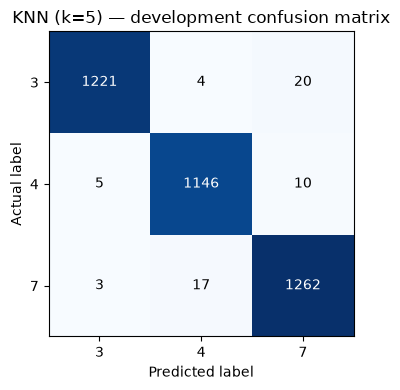

In [54]:
matrix = confusion_matrix_manual(
    y_dev, knn_val_predictions[best_k]
)
labels = np.unique(np.concatenate([
    y_dev, knn_val_predictions[best_k]
]))

plt.figure(figsize=(5, 4))
plt.imshow(matrix, cmap="Blues")

for row in range(len(labels)):
    for column in range(len(labels)):
        plt.text(
            column, row, matrix[row, column],
            ha="center", va="center",
            color="white" if matrix[row, column] > matrix.max() / 2
            else "black"
        )

plt.xticks(range(len(labels)), labels)
plt.yticks(range(len(labels)), labels)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title(f"KNN (k={best_k}) — development confusion matrix")
plt.tight_layout()
plt.show()

In [20]:
#GMM
component_values = [1, 2, 3, 4]

gmm_models = {}
gmm_val_predictions = {}
gmm_rows = []

for components in component_values:
    print(
        f"Training GMM with {components} component(s) per class...",
        flush=True
    )

    model = GMMClassifier(
        n_components=components,
        max_iter=150,
        tol=1e-5,
        regularization=1e-5
    )

    model.fit(X_train_scaled, y_train)

    predictions = model.predict(X_dev_scaled)

    accuracy = accuracy_score_manual(
        y_dev, predictions
    )

    gmm_models[components] = model
    gmm_val_predictions[components] = predictions

    gmm_rows.append({
        "Components per class": components,
        "Validation accuracy (%)": 100 * accuracy,
        "Class 0 EM updates": model.models_[0].n_iter_,
        "Class 1 EM updates": model.models_[1].n_iter_,
        "Both converged": all(
            fitted_model.converged_
            for fitted_model in model.models_
        )
    })

gmm_validation_table = pd.DataFrame(gmm_rows)

print("\nGMM validation comparison:")
print(gmm_validation_table.to_string(index=False))

Training GMM with 1 component(s) per class...
Training GMM with 2 component(s) per class...
Training GMM with 3 component(s) per class...
Training GMM with 4 component(s) per class...

GMM validation comparison:
 Components per class  Validation accuracy (%)  Class 0 EM updates  Class 1 EM updates  Both converged
                    1                95.498915                   1                   1            True
                    2                94.278742                   5                   6            True
                    3                94.007592                   6                   6            True
                    4                92.136659                   5                  47            True


Selected components per class: 1

GMM (1 component(s) per class) validation accuracy: 95.499%

Confusion matrix:
          Predicted 3  Predicted 4  Predicted 7
Actual 3         1206           14           25
Actual 4           32         1108           21
Actual 7           27           47         1208


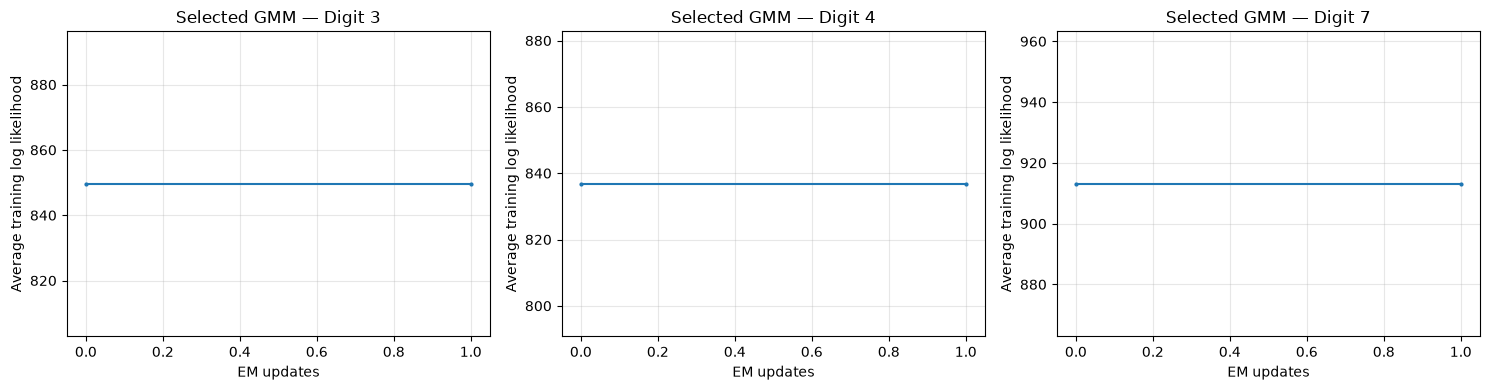

In [24]:
# Check convergence directly from the fitted class models.
gmm_validation_table["All classes converged"] = [
    all(
        fitted_model.converged_
        for fitted_model in gmm_models[int(components)].models_
    )
    for components in gmm_validation_table["Components per class"]
]

# Keep only fully converged candidates.
converged_candidates = gmm_validation_table[
    gmm_validation_table["All classes converged"]
].copy()

if converged_candidates.empty:
    raise RuntimeError(
        "No GMM candidate fully converged. "
        "Increase max_iter in the GMM training cell "
        "and rerun that cell."
    )

# Highest validation accuracy wins.
# If accuracies tie, choose fewer components.
ranked_candidates = converged_candidates.sort_values(
    by=["Validation accuracy (%)", "Components per class"],
    ascending=[False, True]
)

best_components = int(
    ranked_candidates.iloc[0]["Components per class"]
)

best_gmm_model = gmm_models[best_components]

print(f"Selected components per class: {best_components}\n")

best_gmm_val_accuracy = show_evaluation(
    f"GMM ({best_components} component(s) per class)",
    y_dev,
    gmm_val_predictions[best_components]
)

# Preserve the variable used by the MNIST comparison table.
gmm_accuracy = best_gmm_val_accuracy

# Plot one convergence curve per class.
n_classes = len(best_gmm_model.classes_)

fig, axes = plt.subplots(
    1,
    n_classes,
    figsize=(5 * n_classes, 4),
    squeeze=False
)

for ax, class_label, model in zip(
    axes.ravel(),
    best_gmm_model.classes_,
    best_gmm_model.models_
):
    history = model.log_likelihood_history_

    ax.plot(
        range(len(history)),
        history,
        marker=".",
        markersize=4
    )

    ax.set_title(f"Selected GMM — Digit {class_label}")
    ax.set_xlabel("EM updates")
    ax.set_ylabel("Average training log likelihood")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

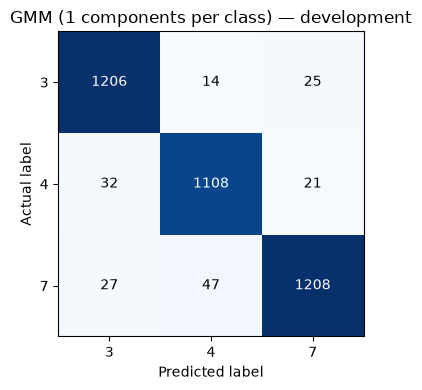

In [55]:
matrix = confusion_matrix_manual(
    y_dev, gmm_val_predictions[best_components]
)
labels = np.unique(np.concatenate([
    y_dev, gmm_val_predictions[best_components]
]))

plt.figure(figsize=(5, 4))
plt.imshow(matrix, cmap="Blues")

for row in range(len(labels)):
    for column in range(len(labels)):
        plt.text(
            column, row, matrix[row, column],
            ha="center", va="center",
            color="white" if matrix[row, column] > matrix.max() / 2
            else "black"
        )

plt.xticks(range(len(labels)), labels)
plt.yticks(range(len(labels)), labels)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title(
    f"GMM ({best_components} components per class) — development"
)
plt.tight_layout()
plt.show()

In [30]:
#SVM
C_values = [0.01, 0.1, 1.0, 10.0, 100.0]

svm_models = {}
svm_val_predictions = {}
svm_rows = []

for C in C_values:
    print(
        f"Training one-versus-rest linear SVM with C={C}...",
        flush=True
    )

    model = OneVsRestSVM(
        C=C,
        max_iter=2000
    )

    # Learn from training data.
    model.fit(X_train_scaled, y_train)

    # Evaluate on development data.
    predictions = model.predict(X_dev_scaled)

    accuracy = accuracy_score_manual(
        y_dev,
        predictions
    )

    svm_models[C] = model
    svm_val_predictions[C] = predictions

    row = {
        "C": C,
        "Validation accuracy (%)": 100 * accuracy,
        "All classes converged": model.converged_
    }

    # Each digit has its own binary SVM and optimizer result.
    for digit, binary_model in zip(
        model.classes_,
        model.models_
    ):
        row[f"Digit {digit} iterations"] = binary_model.n_iter_

        if not binary_model.converged_:
            print(
                f"Digit {digit} optimizer message:",
                binary_model.optimization_result_.message
            )

    svm_rows.append(row)

svm_validation_table = pd.DataFrame(svm_rows)

print("\nLinear SVM development comparison:")
print(
    svm_validation_table.round(3).to_string(index=False)
)

# Consider only candidates where every binary SVM converged.
converged_svm_candidates = svm_validation_table[
    svm_validation_table["All classes converged"]
].copy()

if converged_svm_candidates.empty:
    raise RuntimeError(
        "No SVM candidate fully converged. "
        "Check the optimizer messages before continuing."
    )

# Highest accuracy wins; smaller C wins an accuracy tie.
ranked_svm_candidates = converged_svm_candidates.sort_values(
    by=["Validation accuracy (%)", "C"],
    ascending=[False, True]
)

best_C = float(
    ranked_svm_candidates.iloc[0]["C"]
)

best_svm_model = svm_models[best_C]

print(f"\nSelected C: {best_C}\n")

best_svm_val_accuracy = show_evaluation(
    f"Linear SVM, one-versus-rest (C={best_C})",
    y_dev,
    svm_val_predictions[best_C]
)

# Preserve the variable used by the MNIST comparison table.
svm_accuracy = best_svm_val_accuracy

Training one-versus-rest linear SVM with C=0.01...
Training one-versus-rest linear SVM with C=0.1...
Training one-versus-rest linear SVM with C=1.0...
Training one-versus-rest linear SVM with C=10.0...
Training one-versus-rest linear SVM with C=100.0...

Linear SVM development comparison:
     C  Validation accuracy (%)  All classes converged  Digit 3 iterations  Digit 4 iterations  Digit 7 iterations
  0.01                   95.770                   True                  13                  12                  12
  0.10                   96.963                   True                  19                  16                  17
  1.00                   98.021                   True                  38                  39                  34
 10.00                   98.454                   True                  79                  83                  95
100.00                   98.346                   True                 174                 205                 222

Selected C: 10.0

L

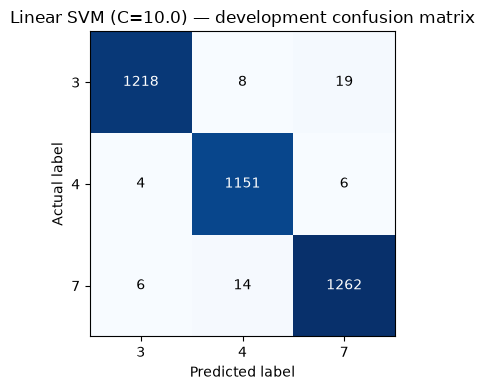

In [56]:
predictions = svm_val_predictions[best_C]

matrix = confusion_matrix_manual(y_dev, predictions)
labels = np.unique(np.concatenate([y_dev, predictions]))

plt.figure(figsize=(5, 4))
plt.imshow(matrix, cmap="Blues")

for row in range(len(labels)):
    for column in range(len(labels)):
        plt.text(
            column, row, matrix[row, column],
            ha="center", va="center",
            color="white" if matrix[row, column] > matrix.max() / 2
            else "black"
        )

plt.xticks(range(len(labels)), labels)
plt.yticks(range(len(labels)), labels)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title(f"Linear SVM (C={best_C}) — development confusion matrix")
plt.tight_layout()
plt.show()

In [31]:
validation_results = [
    {
        "Classifier": "LDA",
        "Setting": "Shared covariance",
        "Development accuracy (%)": 100 * lda_val_accuracy
    },
    {
        "Classifier": "KNN",
        "Setting": f"k={best_k}",
        "Development accuracy (%)": 100 * best_knn_val_accuracy
    },
    {
        "Classifier": "GMM",
        "Setting": f"{best_components} component(s) per class",
        "Development accuracy (%)": 100 * best_gmm_val_accuracy
    },
    {
        "Classifier": "Linear SVM",
        "Setting": f"One-versus-rest, C={best_C}",
        "Development accuracy (%)": 100 * best_svm_val_accuracy
    }
]

validation_comparison = pd.DataFrame(validation_results)

print("MNIST — original 784 features: development comparison")
print(
    validation_comparison.round(3).to_string(index=False)
)

MNIST — original 784 features: development comparison
Classifier                  Setting  Development accuracy (%)
       LDA        Shared covariance                    97.017
       KNN                      k=5                    98.400
       GMM 1 component(s) per class                    95.499
Linear SVM  One-versus-rest, C=10.0                    98.454


Components needed for at least 95% variance: 280


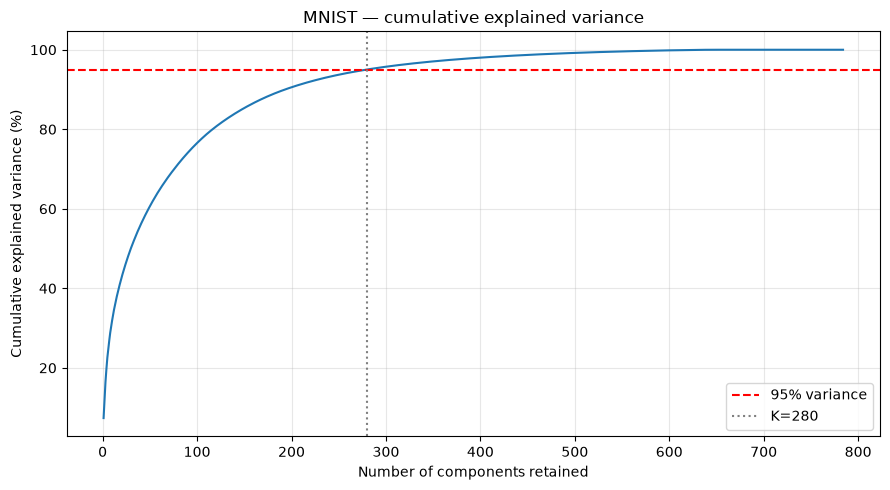

In [32]:
# Fit using standardized training data only.
pca_model = PCA()
pca_model.fit(X_train_scaled)

n_features = X_train_scaled.shape[1]
component_numbers = np.arange(1, n_features + 1)

K_95 = int(
    np.flatnonzero(
        pca_model.cumulative_variance_ >= 0.95 - 1e-12
    )[0] + 1
)

print(f"Components needed for at least 95% variance: {K_95}")

plt.figure(figsize=(9, 5))

plt.plot(
    component_numbers,
    100 * pca_model.cumulative_variance_
)

plt.axhline(
    95,
    color="red",
    linestyle="--",
    label="95% variance"
)

plt.axvline(
    K_95,
    color="gray",
    linestyle=":",
    label=f"K={K_95}"
)

plt.xlabel("Number of components retained")
plt.ylabel("Cumulative explained variance (%)")
plt.title("MNIST — cumulative explained variance")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [33]:
K_values = [10, 20, 30, 50, 100, 150]

# Compute projections up to the largest K needed.
X_train_pca_all = pca_model.transform(
    X_train_scaled,
    n_components=max(K_values)
)

X_dev_pca_all = pca_model.transform(
    X_dev_scaled,
    n_components=max(K_values)
)

In [34]:
neighbor_values = [3, 5, 7, 11]
component_values = [1, 2, 3, 4]
C_values = [0.01, 0.1, 1.0, 10.0, 100.0]

pca_results = []
pca_selected_models = {}
pca_tuning_rows = []

for K in K_values:
    print(f"Processing PCA K={K}...", flush=True)

    train_features = X_train_pca_all[:, :K]
    dev_features = X_dev_pca_all[:, :K]

    # --------------------------------------------------
    # LDA
    # --------------------------------------------------
    lda = LDA()
    lda.fit(train_features, y_train)

    lda_accuracy_pca = accuracy_score_manual(
        y_dev,
        lda.predict(dev_features)
    )

    # --------------------------------------------------
    # KNN: select neighbour count
    # --------------------------------------------------
    knn = KNN(batch_size=128)
    knn.fit(train_features, y_train)

    knn_predictions = knn.predict_for_k_values(
        dev_features,
        neighbor_values
    )

    knn_scores = {}

    for neighbours in neighbor_values:
        accuracy = accuracy_score_manual(
            y_dev,
            knn_predictions[neighbours]
        )

        knn_scores[neighbours] = accuracy

        pca_tuning_rows.append({
            "K": K,
            "Classifier": "KNN",
            "Setting": f"k={neighbours}",
            "Development accuracy (%)": 100 * accuracy,
            "Converged": True
        })

    # Smaller k wins an accuracy tie.
    selected_neighbours = max(
        sorted(knn_scores),
        key=lambda k: knn_scores[k]
    )

    knn_accuracy_pca = knn_scores[selected_neighbours]

    # --------------------------------------------------
    # GMM: select components per class
    # --------------------------------------------------
    selected_gmm = None
    selected_components = None
    gmm_accuracy_pca = -np.inf

    for components in component_values:
        gmm = GMMClassifier(
            n_components=components,
            max_iter=150,
            tol=1e-5,
            regularization=1e-5
        )

        try:
            gmm.fit(train_features, y_train)

            accuracy = accuracy_score_manual(
                y_dev,
                gmm.predict(dev_features)
            )

            converged = all(
                model.converged_
                for model in gmm.models_
            )

        except (ValueError, np.linalg.LinAlgError) as error:
            print(
                f"  GMM components={components} failed: {error}",
                flush=True
            )

            pca_tuning_rows.append({
                "K": K,
                "Classifier": "GMM",
                "Setting": f"components={components}",
                "Development accuracy (%)": np.nan,
                "Converged": False
            })

            continue

        pca_tuning_rows.append({
            "K": K,
            "Classifier": "GMM",
            "Setting": f"components={components}",
            "Development accuracy (%)": 100 * accuracy,
            "Converged": converged
        })

        if not converged:
            print(
                f"  GMM components={components}: "
                "not all class models converged; excluded.",
                flush=True
            )

        # Smaller component count wins an accuracy tie.
        if converged and accuracy > gmm_accuracy_pca:
            selected_gmm = gmm
            selected_components = components
            gmm_accuracy_pca = accuracy

    if selected_gmm is None:
        raise RuntimeError(
            f"No GMM candidate fully converged for K={K}. "
            "Inspect diagnostics before continuing."
        )

    # --------------------------------------------------
    # One-versus-rest linear SVM: select C
    # --------------------------------------------------
    selected_svm = None
    selected_C = None
    svm_accuracy_pca = -np.inf

    for C in C_values:
        svm = OneVsRestSVM(
            C=C,
            max_iter=2000
        )

        svm.fit(train_features, y_train)

        accuracy = accuracy_score_manual(
            y_dev,
            svm.predict(dev_features)
        )

        pca_tuning_rows.append({
            "K": K,
            "Classifier": "Linear SVM",
            "Setting": f"C={C}",
            "Development accuracy (%)": 100 * accuracy,
            "Converged": svm.converged_
        })

        if not svm.converged_:
            for digit, binary_model in zip(
                svm.classes_,
                svm.models_
            ):
                if not binary_model.converged_:
                    print(
                        f"  SVM C={C}, digit {digit}: "
                        f"{binary_model.optimization_result_.message}",
                        flush=True
                    )

        # Smaller C wins an accuracy tie.
        if svm.converged_ and accuracy > svm_accuracy_pca:
            selected_svm = svm
            selected_C = C
            svm_accuracy_pca = accuracy

    if selected_svm is None:
        raise RuntimeError(
            f"No SVM candidate fully converged for K={K}."
        )

    # --------------------------------------------------
    # Store selected models and development results
    # --------------------------------------------------
    pca_selected_models[K] = {
        "LDA": lda,
        "KNN": knn,
        "KNN neighbours": selected_neighbours,
        "GMM": selected_gmm,
        "GMM components": selected_components,
        "Linear SVM": selected_svm,
        "SVM C": selected_C
    }

    pca_results.append({
        "K": K,
        "Retained variance (%)": (
            100 * pca_model.cumulative_variance_[K - 1]
        ),
        "LDA": 100 * lda_accuracy_pca,
        "KNN": 100 * knn_accuracy_pca,
        "GMM": 100 * gmm_accuracy_pca,
        "Linear SVM": 100 * svm_accuracy_pca,
        "KNN neighbours": selected_neighbours,
        "GMM components": selected_components,
        "SVM C": selected_C
    })

pca_results_table = pd.DataFrame(pca_results)
pca_tuning_table = pd.DataFrame(pca_tuning_rows)

print("\nMNIST — PCA development results (%):")
print(
    pca_results_table.round(3).to_string(index=False)
)

Processing PCA K=10...
Processing PCA K=20...
Processing PCA K=30...
Processing PCA K=50...
Processing PCA K=100...
Processing PCA K=150...

MNIST — PCA development results (%):
  K  Retained variance (%)    LDA    KNN    GMM  Linear SVM  KNN neighbours  GMM components  SVM C
 10                 31.871 95.336 98.292 97.831      96.611               5               4  100.0
 20                 42.675 95.879 98.807 97.560      96.855               3               3   10.0
 30                 50.112 96.014 98.888 97.126      97.099               3               2  100.0
 50                 60.637 96.394 98.970 97.099      97.533               3               1   10.0
100                 76.544 96.746 98.861 97.072      98.156               3               1   10.0
150                 85.349 96.990 98.753 96.828      98.183               5               1  100.0


In [39]:
classifier_names = ["LDA", "KNN", "GMM", "Linear SVM"]

original_test_predictions = {
    "LDA": lda_model.predict(X_test_scaled),

    "KNN": knn_model.predict_for_k_values(
        X_test_scaled,
        [best_k]
    )[best_k],

    "GMM": best_gmm_model.predict(X_test_scaled),

    "Linear SVM": best_svm_model.predict(X_test_scaled)
}

original_settings = {
    "LDA": "Shared covariance",
    "KNN": f"k={best_k}",
    "GMM": f"{best_components} component(s) per class",
    "Linear SVM": f"One-versus-rest, C={best_C}"
}

original_test_rows = []

for classifier in classifier_names:
    predictions = original_test_predictions[classifier]

    correct = int(np.sum(predictions == y_test))
    errors = len(y_test) - correct

    original_test_rows.append({
        "Classifier": classifier,
        "Setting": original_settings[classifier],
        "Correct": correct,
        "Errors": errors,
        "Test accuracy (%)": (
            100 * accuracy_score_manual(y_test, predictions)
        )
    })

original_test_table = pd.DataFrame(original_test_rows)

n_features = X_train_scaled.shape[1]

print(f"MNIST — original {n_features} features: test results")
print(
    original_test_table.round(3).to_string(index=False)
)

MNIST — original 784 features: test results
Classifier                  Setting  Correct  Errors  Test accuracy (%)
       LDA        Shared covariance     2935      85             97.185
       KNN                      k=5     2968      52             98.278
       GMM 1 component(s) per class     2892     128             95.762
Linear SVM  One-versus-rest, C=10.0     2964      56             98.146


In [40]:
# Transform test data using the training-fitted PCA.
X_test_pca_all = pca_model.transform(
    X_test_scaled,
    n_components=max(K_values)
)

pca_test_predictions = {}
pca_test_rows = []

for K in K_values:
    test_features = X_test_pca_all[:, :K]
    selected = pca_selected_models[K]

    selected_neighbours = selected["KNN neighbours"]

    predictions = {
        "LDA": selected["LDA"].predict(
            test_features
        ),

        "KNN": selected["KNN"].predict_for_k_values(
            test_features,
            [selected_neighbours]
        )[selected_neighbours],

        "GMM": selected["GMM"].predict(
            test_features
        ),

        "Linear SVM": selected["Linear SVM"].predict(
            test_features
        )
    }

    pca_test_predictions[K] = predictions

    result_row = {
        "K": K,
        "Retained training variance (%)": (
            100 * pca_model.cumulative_variance_[K - 1]
        )
    }

    for classifier in classifier_names:
        result_row[classifier] = (
            100 * accuracy_score_manual(
                y_test,
                predictions[classifier]
            )
        )

    pca_test_rows.append(result_row)

pca_test_table = pd.DataFrame(pca_test_rows)

In [57]:
n_features = X_train_scaled.shape[1]

original_test_accuracies = dict(zip(
    original_test_table["Classifier"],
    original_test_table["Test accuracy (%)"]
))

column_order = ["LDA", "KNN", "Linear SVM", "GMM"]

final_rows = [{
    "K": f"Original ({n_features})",
    **{
        classifier: original_test_accuracies[classifier]
        for classifier in column_order
    }
}]

for _, row in pca_test_table.iterrows():
    final_rows.append({
        "K": int(row["K"]),
        **{
            classifier: row[classifier]
            for classifier in column_order
        }
    })

final_test_comparison = pd.DataFrame(final_rows)

# Shorten the displayed column heading.
display_table = final_test_comparison.rename(
    columns={"Linear SVM": "SVM"}
)

print("MNIST — original versus PCA: TEST accuracy (%)")
display(display_table.round(2))

MNIST — original versus PCA: TEST accuracy (%)


,K,LDA,KNN,SVM,GMM
0,Original (784),97.19,98.28,98.15,95.76
1,10,96.06,98.31,96.56,97.88
2,20,96.16,98.54,97.19,97.58
3,30,96.23,98.64,97.42,97.28
4,50,96.59,98.54,97.19,97.19
5,100,96.95,98.28,97.75,97.19
6,150,97.15,98.38,97.81,96.95


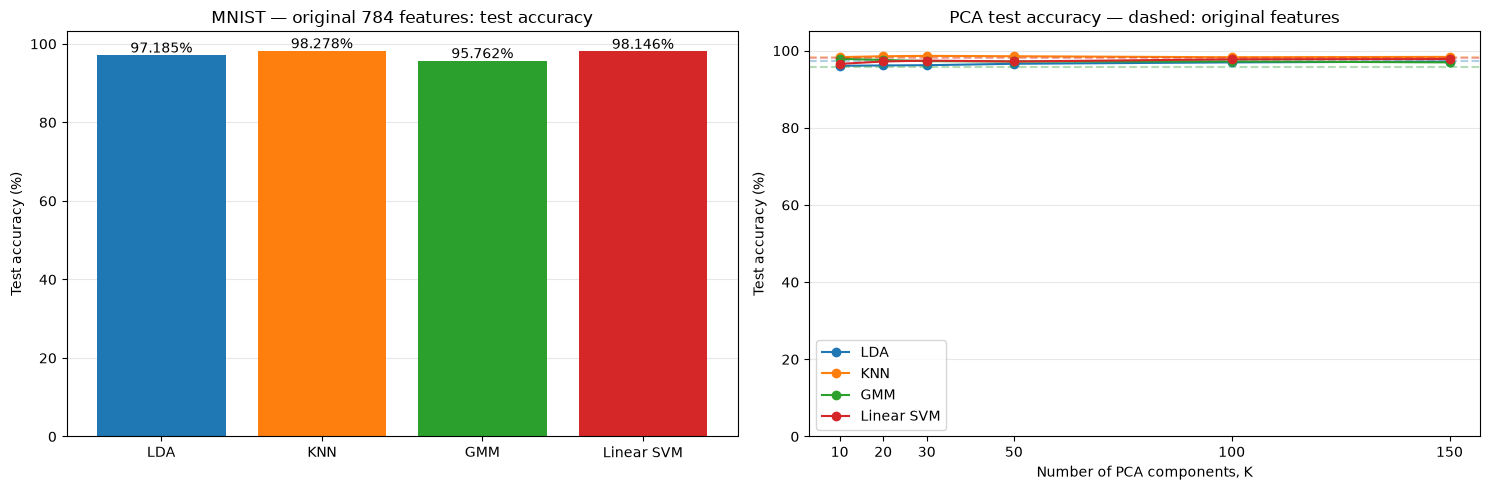

In [58]:
colors = {
    "LDA": "tab:blue",
    "KNN": "tab:orange",
    "GMM": "tab:green",
    "Linear SVM": "tab:red"
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Original-feature test accuracies.
bars = axes[0].bar(
    classifier_names,
    [
        original_test_accuracies[name]
        for name in classifier_names
    ],
    color=[colors[name] for name in classifier_names]
)

for bar, classifier in zip(bars, classifier_names):
    accuracy = original_test_accuracies[classifier]

    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        accuracy + 0.6,
        f"{accuracy:.3f}%",
        ha="center"
    )

axes[0].set_title(
    f"MNIST — original {n_features} features: test accuracy"
)
axes[0].set_ylabel("Test accuracy (%)")
axes[1].set_title(
    "MNIST — PCA test accuracy; dashed: original features"
)

# PCA test accuracies.
for classifier in classifier_names:
    axes[1].plot(
        pca_test_table["K"],
        pca_test_table[classifier],
        marker="o",
        color=colors[classifier],
        label=classifier
    )

    axes[1].axhline(
        original_test_accuracies[classifier],
        color=colors[classifier],
        linestyle="--",
        alpha=0.35
    )

axes[1].set_title("PCA test accuracy — dashed: original features")
axes[1].set_xlabel("Number of PCA components, K")
axes[1].set_ylabel("Test accuracy (%)")
axes[1].set_xticks(K_values)
axes[1].set_ylim(0, 105)
axes[1].legend()

for ax in axes:
    ax.grid(axis="y", alpha=0.3)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [59]:
from IPython.display import display

development_accuracy_lookup = dict(zip(
    validation_comparison["Classifier"],
    validation_comparison["Development accuracy (%)"]
))

validation_test_rows = []

for classifier in classifier_names:
    development_accuracy = development_accuracy_lookup[classifier]
    test_accuracy = original_test_accuracies[classifier]

    validation_test_rows.append({
        "Classifier": classifier,
        "Development accuracy (%)": development_accuracy,
        "Test accuracy (%)": test_accuracy,
        "Test minus development (percentage points)": (
            test_accuracy - development_accuracy
        )
    })

validation_test_comparison = pd.DataFrame(
    validation_test_rows
)

print("MNIST — original features: development versus test")
display(validation_test_comparison.round(3))

MNIST — original features: development versus test


,Classifier,Development accuracy (%),Test accuracy (%),Test minus development (percentage points)
0,LDA,97.017,97.185,0.168
1,KNN,98.400,98.278,-0.122
2,GMM,95.499,95.762,0.263
3,Linear SVM,98.454,98.146,-0.309


In [60]:
results = pca_results_table.melt(
    id_vars="K",
    value_vars=["LDA", "KNN", "GMM", "Linear SVM"],
    var_name="Classifier",
    value_name="Accuracy"
)

# Highest development accuracy wins.
# If tied, prefer fewer PCA components.
best_pca = results.sort_values(
    by=["Accuracy", "K", "Classifier"],
    ascending=[False, True, True]
).iloc[0]

print("MNIST — best tested PCA model")
print("Classifier:", best_pca["Classifier"])
print("PCA components:", int(best_pca["K"]))
print(f"Validation Accuracy: {best_pca['Accuracy']:.3f}%")

MNIST — best tested PCA model
Classifier: KNN
PCA components: 50
Validation Accuracy: 98.970%


MNIST — selected model: final test result
Classifier: KNN
PCA components: 50
Test accuracy: 98.543%


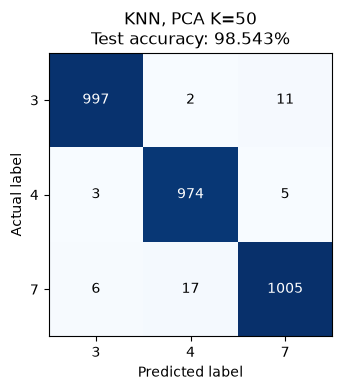

In [62]:
selected_K = int(best_pca["K"])
selected_classifier = best_pca["Classifier"]

selected_test_accuracy = (
    pca_test_table.set_index("K")
    .loc[selected_K, selected_classifier]
)

print("MNIST — selected model: final test result")
print("Classifier:", selected_classifier)
print("PCA components:", selected_K)
print(f"Test accuracy: {selected_test_accuracy:.3f}%")

predictions = pca_test_predictions[selected_K][selected_classifier]

matrix = confusion_matrix_manual(y_test, predictions)
labels = np.unique(np.concatenate([y_test, predictions]))

plt.figure(figsize=(5, 4))
plt.imshow(matrix, cmap="Blues")

for row in range(len(labels)):
    for column in range(len(labels)):
        plt.text(
            column, row, matrix[row, column],
            ha="center",
            va="center",
            color="white" if matrix[row, column] > matrix.max() / 2
            else "black"
        )

plt.xticks(range(len(labels)), labels)
plt.yticks(range(len(labels)), labels)
plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.title(
    f"{selected_classifier}, PCA K={selected_K}\n"
    f"Test accuracy: {selected_test_accuracy:.3f}%"
)
plt.tight_layout()
plt.show()

## Discussion and Conclusion

The classifiers were compared on MNIST digits 3, 4, and 7 using
all 784 features and different numbers of PCA components.

The final table shows how each classifier’s test accuracy changes
after PCA. Retaining more variance does not necessarily produce
higher classification accuracy.

The final model and PCA dimension were selected using development
accuracy. Its test accuracy and confusion matrix show its performance
on unseen samples and which digits were confused.

PCA allows classification with fewer features, but its effect on
accuracy depends on the classifier and the number of components retained.